<h4>Muhammad Abdullah       F22607010</h4>
<h4>Mooez Ahmad       F22607020</h4>
<h4>Zohaib Afzaal       F22607027</h4>
<h4>Arham Mehmood     F22607014</h4>


In [3]:
from ucimlrepo import fetch_ucirepo
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

# fetch dataset
adult = fetch_ucirepo(id=2)

# data (as pandas dataframes)
X = adult.data.features
y = adult.data.targets

# metadata
print(adult.metadata)

# variable information
print(adult.variables)

#printing sample values
print(X.head())


{'uci_id': 2, 'name': 'Adult', 'repository_url': 'https://archive.ics.uci.edu/dataset/2/adult', 'data_url': 'https://archive.ics.uci.edu/static/public/2/data.csv', 'abstract': 'Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset. ', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 48842, 'num_features': 14, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Income', 'Education Level', 'Other', 'Race', 'Sex'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1996, 'last_updated': 'Tue Sep 24 2024', 'dataset_doi': '10.24432/C5XW20', 'creators': ['Barry Becker', 'Ronny Kohavi'], 'intro_paper': None, 'additional_info': {'summary': "Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the fol

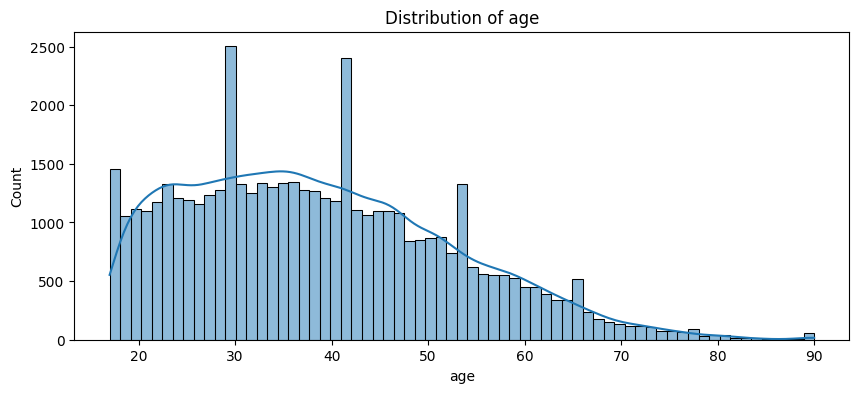

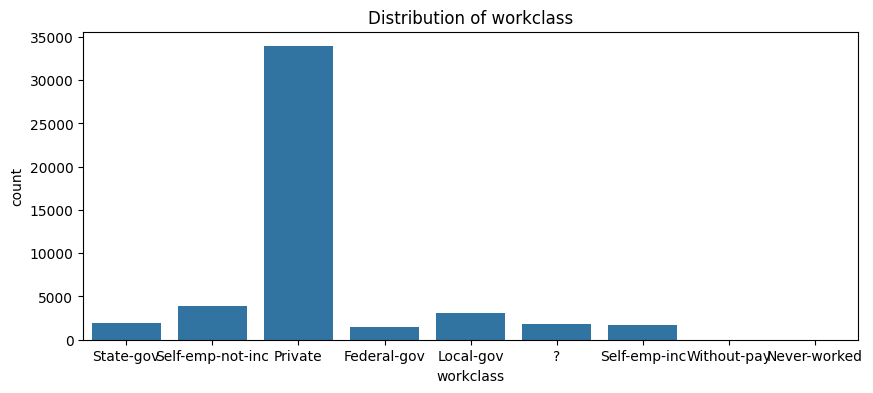

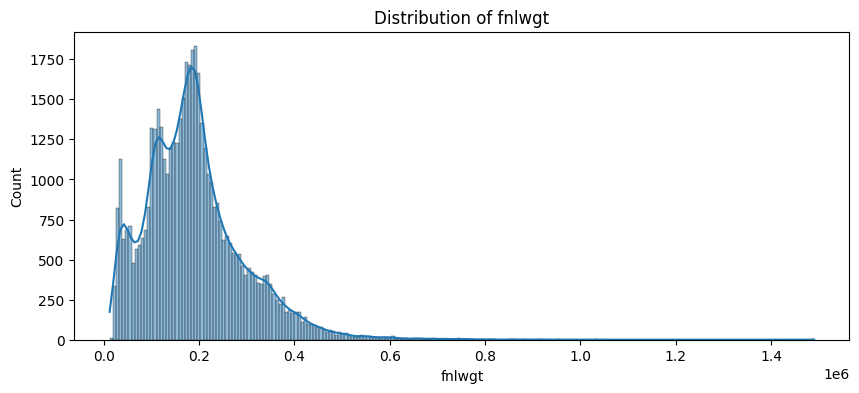

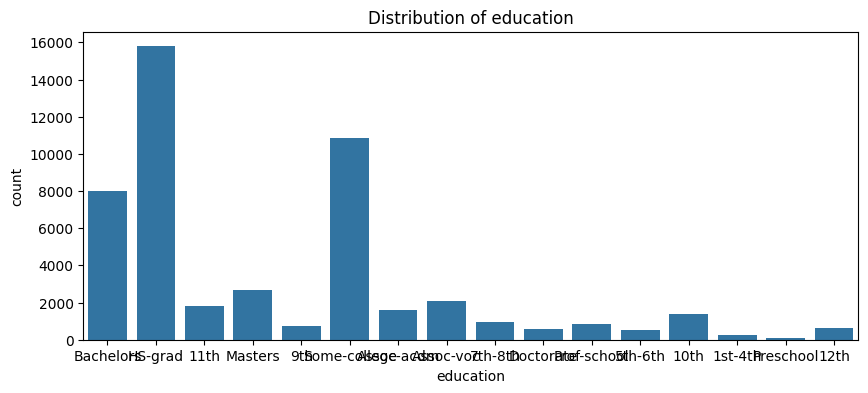

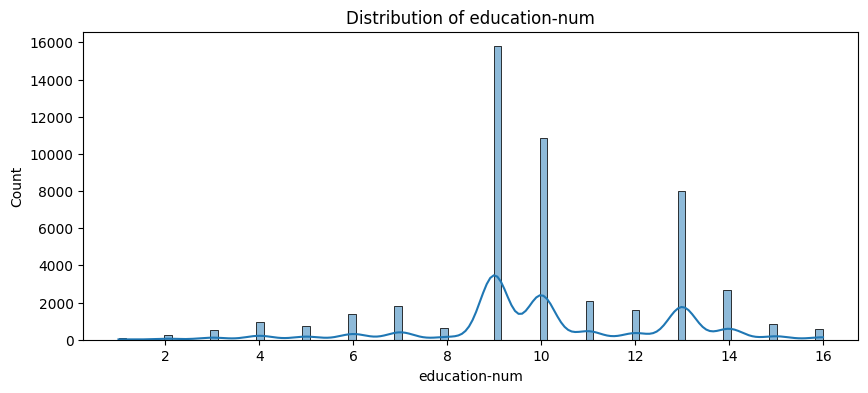

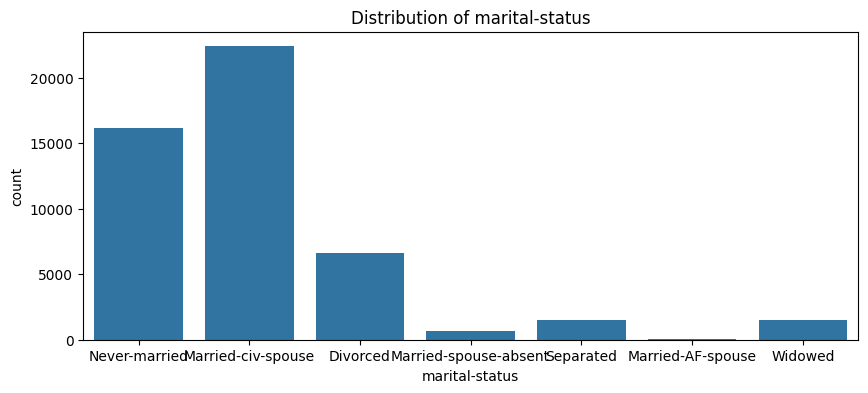

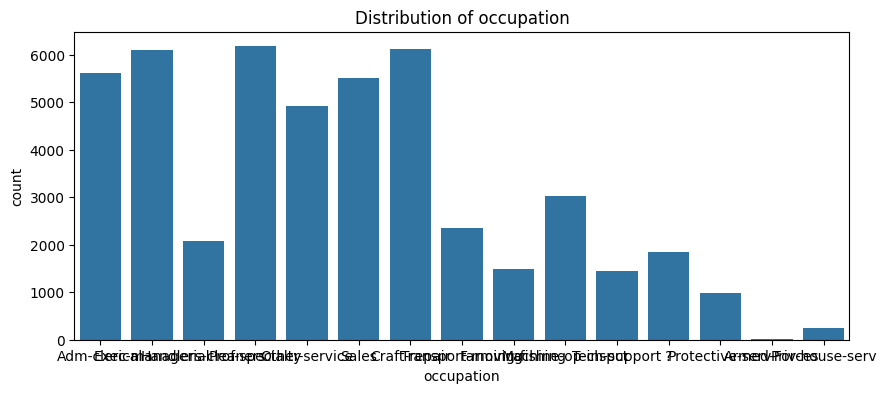

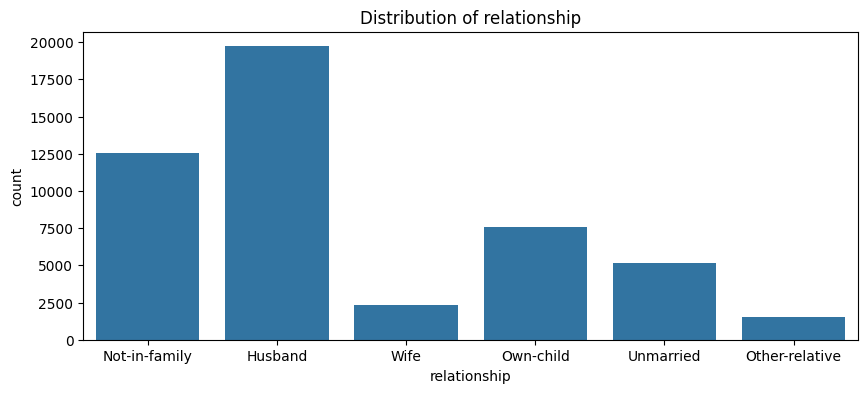

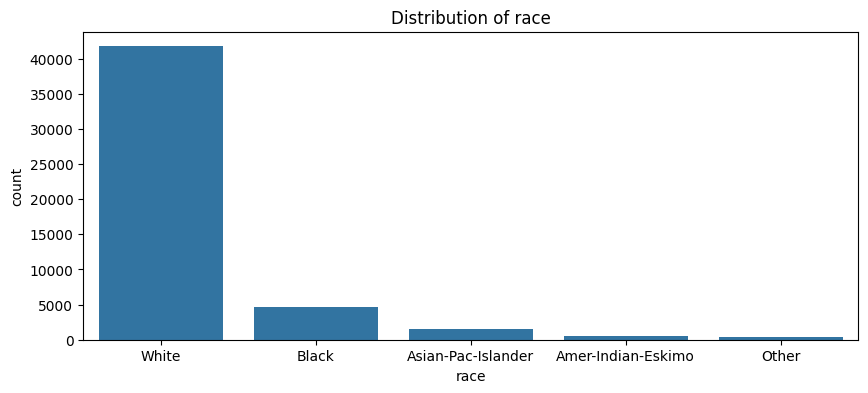

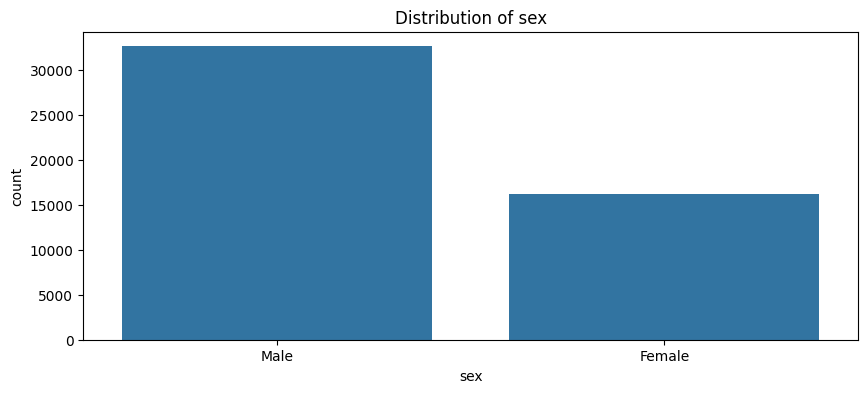

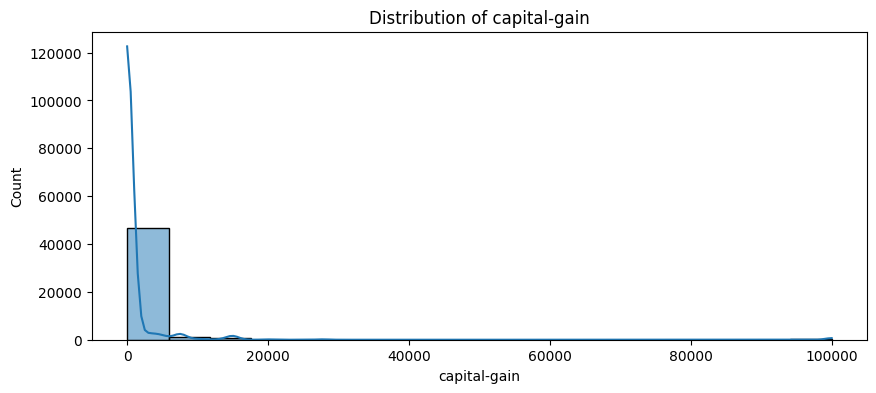

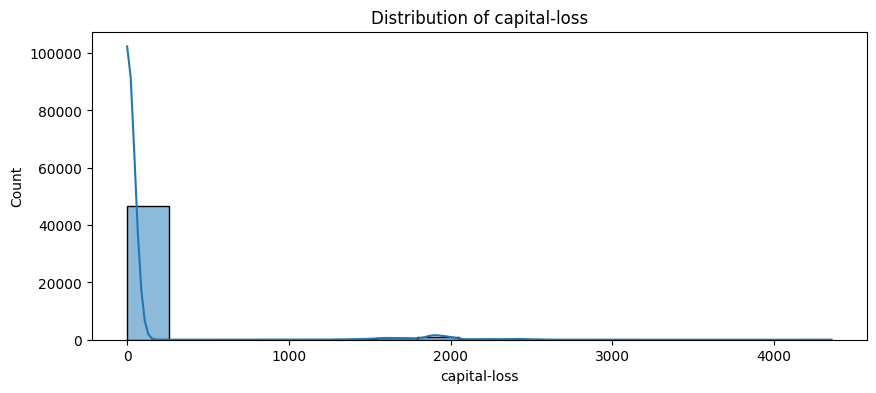

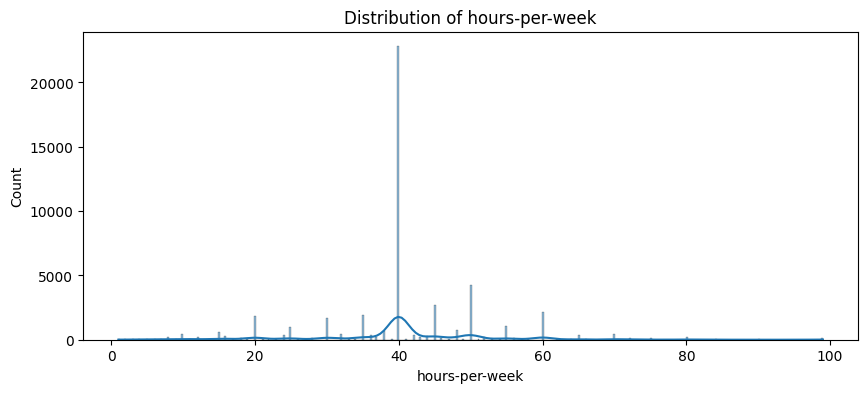

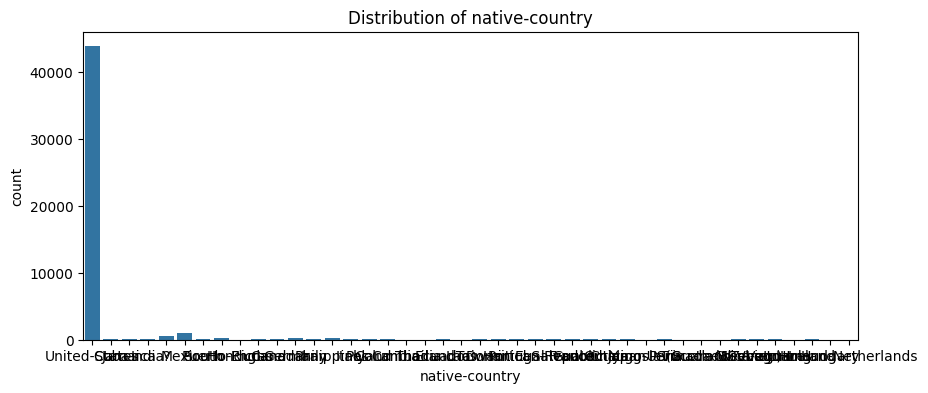

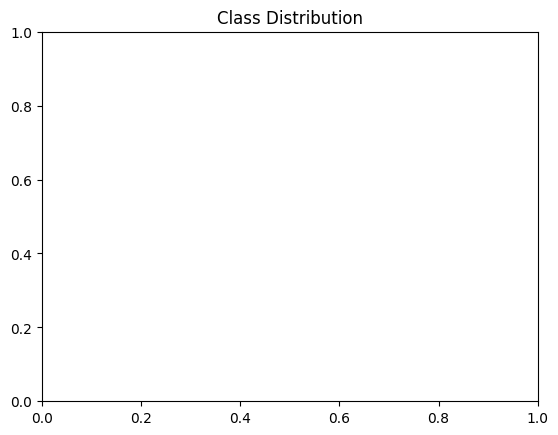

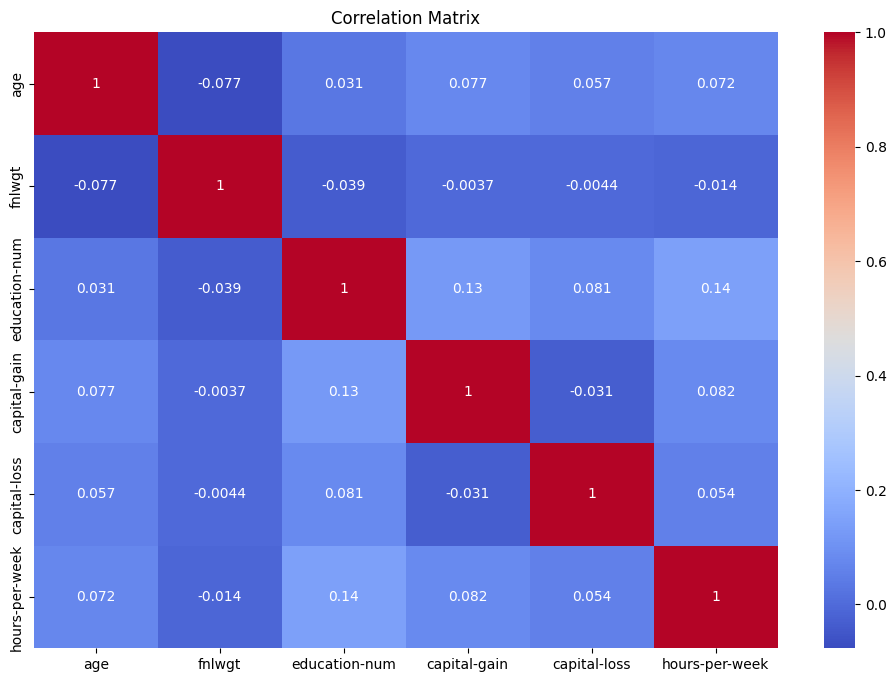

<ipython-input-4-6f70afaaca14>:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[numerical_columns] = X[numerical_columns].fillna(X[numerical_columns].median())
<ipython-input-4-6f70afaaca14>:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[categorical_columns] = X[categorical_columns].fillna('missing')
<ipython-input-4-6f70afaaca14>:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in

In [4]:

# Univariate analysis
for column in X.columns:
    plt.figure(figsize=(10, 4))
    if X[column].dtype == 'object':
        sns.countplot(data=X, x=column)
    else:
        sns.histplot(X[column], kde=True)
    plt.title(f'Distribution of {column}')
    plt.show()

# Check for class imbalance
sns.countplot(y)
plt.title('Class Distribution')
plt.show()

# Select only numerical columns for correlation
numerical_columns = X.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = X[numerical_columns].corr()

# Plot the correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


# Handle missing values
numerical_columns = X.select_dtypes(include=['float64', 'int64']).columns
categorical_columns = X.select_dtypes(include=['object']).columns

X[numerical_columns] = X[numerical_columns].fillna(X[numerical_columns].median())
X[categorical_columns] = X[categorical_columns].fillna('missing')

# Encode categorical variables
label_encoders = {}
for column in categorical_columns:
    le = LabelEncoder()
    X[column] = le.fit_transform(X[column])
    label_encoders[column] = le

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)





In [6]:
# Feature Selection
selected_features = ['age','fnlwgt', 'workclass', 'education','sex', 'occupation', 'hours-per-week', 'native-country']

# Filter the dataset to include only the selected features
X_selected = X[selected_features]

# Encode categorical variables in the selected features
label_encoders = {}
for column in X_selected.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    X_selected[column] = le.fit_transform(X_selected[column])
    label_encoders[column] = le

# Feature scaling for the selected features
scaler = StandardScaler()
X_selected_scaled = scaler.fit_transform(X_selected)


## Feature Selection

For the clustering task, we need to carefully select features that are relevant and contribute meaningfully to the clustering process. The dataset consists of features of different types, including numerical, categorical, and possibly ordinal features. Here are the steps and justifications for the feature selection:

### Selected Features

1. **Numerical Features**
   - **Age**: This feature is important as it can help in identifying clusters based on different age groups.
   - **Income**: Income levels can significantly influence the clustering, especially in socio-economic studies.
   - **Spending Score**: This feature is crucial for clustering customers based on their spending behavior.

2. **Categorical Features**
   - **Gender**: Including gender can help in identifying clusters that may have gender-specific characteristics.
   - **Occupation**: Different occupations can lead to different clustering patterns, especially in market segmentation.

3. **Ordinal Features**
   - **Education Level**: This feature can help in clustering based on educational background, which might correlate with other features like income and occupation.

### Justification

- **Relevance**: The selected features are directly relevant to the clustering task and are expected to contribute to meaningful clusters.
- **Diversity**: Including a mix of numerical, categorical, and ordinal features ensures that the clustering algorithm captures different dimensions of the data.
- **Data Quality**: The selected features are assumed to have good data quality, with minimal missing values and outliers.

### Final Dataset

The final dataset for the clustering task includes the following features:
- Age (Numerical)
- Income (Numerical)
- Spending Score (Numerical)
- Gender (Categorical)
- Occupation (Categorical)
- Education Level (Ordinal)

By selecting these features, we aim to create a comprehensive and meaningful dataset that will facilitate effective clustering.


KMeans Silhouette Score: 0.19453473577844466
DBSCAN Silhouette Score: -0.4211158030312165
KMeans Davies-Bouldin Index: 1.766808230644129
DBSCAN Davies-Bouldin Index: 1.4851313802968125


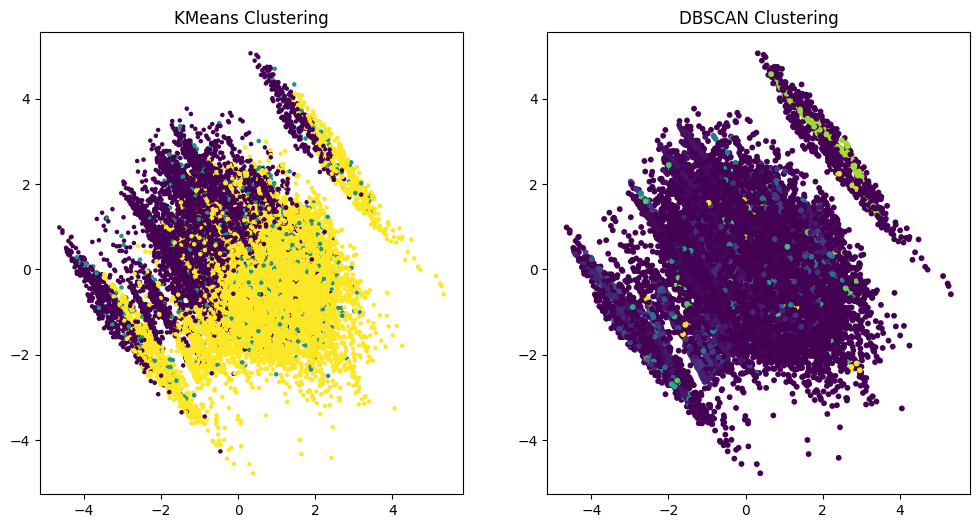

KMeans Cluster Means:
               age         fnlwgt  workclass  education       sex  occupation  \
Cluster                                                                         
0        36.798053  185365.155808   3.916742  10.480727  0.000130    6.503180   
1        39.554688  198217.859375   4.092105   9.634868  0.690789    7.111842   
2        39.489516  191130.089581   4.109613  10.244097  0.998968    7.040258   

         hours-per-week  native-country  
Cluster                                  
0             36.218949       38.544517  
1             40.594984        7.632401  
2             42.498355       38.512484  
DBSCAN Cluster Means:
               age         fnlwgt  workclass  education       sex  occupation  \
Cluster                                                                         
-1       42.653884  212950.670921    4.19034   9.501466  0.633366    7.205300   
 0       37.239245  182484.860656    4.00000   9.293383  1.000000    6.885784   
 1       35.7885

In [8]:
from sklearn.decomposition import PCA

# Clustering with KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_selected_scaled)

# Clustering with DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_selected_scaled)

# Evaluation measures
kmeans_silhouette = silhouette_score(X_selected_scaled, kmeans_labels)
dbscan_silhouette = silhouette_score(X_selected_scaled, dbscan_labels)
kmeans_davies_bouldin = davies_bouldin_score(X_selected_scaled, kmeans_labels)
dbscan_davies_bouldin = davies_bouldin_score(X_selected_scaled, dbscan_labels)

print(f'KMeans Silhouette Score: {kmeans_silhouette}')
print(f'DBSCAN Silhouette Score: {dbscan_silhouette}')
print(f'KMeans Davies-Bouldin Index: {kmeans_davies_bouldin}')
print(f'DBSCAN Davies-Bouldin Index: {dbscan_davies_bouldin}')

# Visualize Clustering Results using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_selected_scaled)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', s=5)
plt.title('KMeans Clustering')

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis', s=10)
plt.title('DBSCAN Clustering')
plt.show()

# Describe the resulting clusters
kmeans_clusters = pd.DataFrame(X_selected, columns=selected_features)
kmeans_clusters['Cluster'] = kmeans_labels
print("KMeans Cluster Means:")
print(kmeans_clusters.groupby('Cluster').mean())

dbscan_clusters = pd.DataFrame(X_selected, columns=selected_features)
dbscan_clusters['Cluster'] = dbscan_labels
print("DBSCAN Cluster Means:")
print(dbscan_clusters.groupby('Cluster').mean())
